# AIML ZG546 - Software Engineering for Machine Learning - Assignment II
## BrakeGuard AI: implementation, code quality and testing

**Group No:** 14

| Sl. No | BITS ID | Name | Contribution of team member (Qualitative) | Percentage Contribution (out of 100) |
|---|---|---|---|---|
| 1 | 2025ae05802 | SAI KRISHNA VIJAYA RAM K | Refactoring into the `brakeguard` package (data, features, models), research-vs-production comparison | 100% |
| 2 | 2025ae05999 | S. S SRINIVAS RAO | FastAPI REST API design (schemas, status codes, error envelope, API-key security), dashboard | 100% |
| 3 | 2025ae05192 | ABHISHEK ARORA | Test strategy and pytest suites (unit, data-quality, ML training/inference, integration), coverage | 100% |
| 4 | 2025ae05200 | RAJESH. R. SHENOI | Logging & error handling, linting/formatting, quality metrics & drift, production-testing & security write-up, report | 100% |


This notebook drives the **production package** `brakeguard/` (it contains no model logic of its
own). Every cell imports from the package, so what is shown here is exactly what the API serves.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rajeshshenoi/Bits-Sem3-SW-Engg-ML/blob/main/BrakeGuard_AI_Assignment_Application/brakeguard_ai-3/notebooks/Group14.ipynb)

### Setup (Google Colab)

The notebook needs the whole project, not just this file. In **Google Colab** the next cell clones
the repository, moves into `brakeguard_ai-3` and installs the dependencies (about 1 minute).
When the notebook runs locally from a checkout, the cell does nothing.

In [104]:
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/rajeshshenoi/Bits-Sem3-SW-Engg-ML.git"
PROJECT_DIR = "BrakeGuard_AI_Assignment_Application/brakeguard_ai-3"

if "google.colab" in sys.modules:
    repo = Path("/content/Bits-Sem3-SW-Engg-ML")
    if repo.exists():
        subprocess.run(["git", "-C", str(repo), "pull", "--ff-only", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(repo)], check=True)
    os.chdir(repo / PROJECT_DIR)
    # Runtime deps + test tools only (Colab already ships Jupyter; reinstalling it can break the kernel)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt",
                    "pytest", "pytest-cov", "httpx"], check=True)
    print("Colab setup complete - working directory:", Path.cwd())
else:
    print("Not running in Colab - using the local checkout:", Path.cwd())

Colab setup complete - working directory: /content/Bits-Sem3-SW-Engg-ML/BrakeGuard_AI_Assignment_Application/brakeguard_ai-3


In [105]:
import json, logging, sys, subprocess
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from brakeguard.config import get_settings
from brakeguard.logging_config import configure_logging
settings = get_settings()
configure_logging("INFO")
print(settings.model_version, settings.thresholds)

brakeguard-rf-v2.0 RiskThresholds(high=0.7, medium=0.4)


## 1. Data ingestion and data-quality validation (Task 1, Task 8b)

In [106]:
from brakeguard.data import SyntheticTelemetrySource, DataValidator
frame = SyntheticTelemetrySource(n_samples=3000, seed=42).load()
report = DataValidator(max_missing_ratio=settings.max_missing_ratio).validate(frame)
frame.head()

2026-11-01 11:40:24,761 | INFO    | brakeguard.data.ingestion | Generated 3000 synthetic telemetry rows (seed=42, shift=0.00, positive rate=0.515)


INFO:brakeguard.data.ingestion:Generated 3000 synthetic telemetry rows (seed=42, shift=0.00, positive rate=0.515)


2026-11-01 11:40:24,785 | INFO    | brakeguard.data.validation | Data validation passed for 3000 rows


INFO:brakeguard.data.validation:Data validation passed for 3000 rows


,vehicle_id,brake_temperature,brake_pressure,pad_wear_pct,vibration_rms,fluid_age_days,odometer_km,fault_within_30d
0,SYN-00000,165.665098,83.735340,34.774127,2.180928,49.092527,168867.066494,1
1,SYN-00001,118.600556,75.315383,26.285796,0.164961,142.060336,179571.251830,0
2,SYN-00002,181.265792,94.491912,8.365035,1.585431,220.994428,133525.116994,0
3,SYN-00003,187.919765,41.782508,16.111400,1.938791,530.068886,132896.746665,1
4,SYN-00004,86.713768,61.019598,62.993392,3.359952,551.018850,21428.186353,1


In [107]:
{k: v for k, v in report.to_dict().items() if k in ("n_rows", "schema_valid", "passed", "overall_missing_ratio", "overall_out_of_range_ratio", "duplicate_ratio")}

{'n_rows': 3000,
 'schema_valid': True,
 'duplicate_ratio': 0.0,
 'passed': True,
 'overall_missing_ratio': 0.0,
 'overall_out_of_range_ratio': 0.0}

A corrupted batch (sensor drop-outs + a unit bug) is rejected by the same validator - note the WARNING/ERROR logs:

In [108]:
import numpy as np
from brakeguard.exceptions import DataValidationError
bad = frame.copy()
bad.loc[bad.index[:300], "brake_temperature"] = np.nan
bad.loc[bad.index[300:400], "pad_wear_pct"] *= 100
try:
    DataValidator().validate_or_raise(bad)
except DataValidationError as exc:
    print("Rejected:", exc.issues)

2026-11-01 11:40:24,898 | WARNING | brakeguard.data.validation | Data validation found 2 issue(s): ["column 'brake_temperature' missing ratio 10.00% exceeds 5.00%", "column 'pad_wear_pct' has 3.33% values outside [0.0, 100.0] %"]


2026-11-01 11:40:24,900 | ERROR   | brakeguard.data.validation | Rejecting data set: column 'brake_temperature' missing ratio 10.00% exceeds 5.00%; column 'pad_wear_pct' has 3.33% values outside [0.0, 100.0] %


ERROR:brakeguard.data.validation:Rejecting data set: column 'brake_temperature' missing ratio 10.00% exceeds 5.00%; column 'pad_wear_pct' has 3.33% values outside [0.0, 100.0] %


Rejected: ["column 'brake_temperature' missing ratio 10.00% exceeds 5.00%", "column 'pad_wear_pct' has 3.33% values outside [0.0, 100.0] %"]


## 2. Training pipeline with quality gates (Task 1, Task 8a)

In [109]:
from dataclasses import replace
from brakeguard.pipeline import TrainingPipeline
nb_settings = replace(settings, model_path=ROOT / "artifacts" / "notebook_model.joblib")
bundle = TrainingPipeline(settings=nb_settings).run(register=True)
bundle.metrics

2026-11-01 11:40:24,912 | INFO    | brakeguard.pipeline | Training pipeline started (model version brakeguard-rf-v2.0)


INFO:brakeguard.pipeline:Training pipeline started (model version brakeguard-rf-v2.0)


2026-11-01 11:40:24,923 | INFO    | brakeguard.data.ingestion | Generated 3000 synthetic telemetry rows (seed=42, shift=0.00, positive rate=0.515)


INFO:brakeguard.data.ingestion:Generated 3000 synthetic telemetry rows (seed=42, shift=0.00, positive rate=0.515)


2026-11-01 11:40:24,937 | INFO    | brakeguard.data.validation | Data validation passed for 3000 rows


INFO:brakeguard.data.validation:Data validation passed for 3000 rows


... (7 outputs left out)

INFO:brakeguard.models.registry:Registered model brakeguard-rf-v2.0 at /content/Bits-Sem3-SW-Engg-ML/BrakeGuard_AI_Assignment_Application/brakeguard_ai-3/artifacts/notebook_model.joblib


2026-11-01 11:40:26,801 | INFO    | brakeguard.pipeline | Training pipeline finished


INFO:brakeguard.pipeline:Training pipeline finished


{'n_samples': 600,
 'threshold': 0.5,
 'accuracy': 0.7767,
 'precision': 0.7692,
 'recall': 0.8091,
 'f1': 0.7886,
 'pr_auc': 0.8375,
 'roc_auc': 0.846,
 'brier_score': 0.1602,
 'expected_calibration_error': 0.034,
 'log_loss': 0.4895}

## 3. Inference with explanations (Task 1)

In [110]:
from brakeguard.models import BrakeFaultPredictor
from brakeguard.features import FeatureStore
predictor = BrakeFaultPredictor(bundle, settings.thresholds)
store = FeatureStore()
for vid in store.vehicle_ids():
    p = predictor.predict(store.get(vid))
    print(f"{vid}: {p.fault_probability:.3f} {p.risk:<6} | {p.explanation}")

2026-11-01 11:40:26,852 | INFO    | brakeguard.models.predictor | Scored 1 record(s) with brakeguard-rf-v2.0


INFO:brakeguard.models.predictor:Scored 1 record(s) with brakeguard-rf-v2.0


BG-10245: 0.972 HIGH   | Main drivers: thermal_wear_index (higher than fleet average), pad_wear_pct (higher than fleet average), vibration_rms (higher than fleet average)
2026-11-01 11:40:26,874 | INFO    | brakeguard.models.predictor | Scored 1 record(s) with brakeguard-rf-v2.0


INFO:brakeguard.models.predictor:Scored 1 record(s) with brakeguard-rf-v2.0


BG-20481: 0.066 LOW    | Main drivers: thermal_wear_index (lower than fleet average), pad_wear_pct (lower than fleet average), brake_temperature (lower than fleet average)
2026-11-01 11:40:26,901 | INFO    | brakeguard.models.predictor | Scored 1 record(s) with brakeguard-rf-v2.0


INFO:brakeguard.models.predictor:Scored 1 record(s) with brakeguard-rf-v2.0


BG-30991: 0.795 HIGH   | Main drivers: thermal_wear_index (higher than fleet average), pad_wear_pct (higher than fleet average), pressure_deviation (lower than fleet average)


Production input validation: the impossible input that the research notebook scored is rejected by the API schema.

In [111]:
from pydantic import ValidationError
from brakeguard.api.schemas import TelemetryFeatures
try:
    TelemetryFeatures(brake_temperature=186.4, brake_pressure=72.1, pad_wear_pct=450, vibration_rms=3.2, fluid_age_days=410, odometer_km=84250)
except ValidationError as exc:
    print(exc.errors()[0]["loc"], exc.errors()[0]["msg"])

('pad_wear_pct',) Input should be less than or equal to 100


## 4. REST API (Task 5) - exercised in-process with FastAPI's TestClient

In [112]:
from fastapi.testclient import TestClient
from brakeguard.api import create_app
client = TestClient(create_app(settings=nb_settings, bundle=bundle))
r = client.post("/api/v1/predictions", json={"vehicle_id": "BG-10245", "telemetry": store.get("BG-10245")})
print(r.status_code); print(json.dumps(r.json(), indent=2))

2026-11-01 11:40:26,948 | INFO    | brakeguard.monitoring.events | Subscriber 'FeatureStoreConsumer' registered for BrakeTelemetryReceived


INFO:brakeguard.monitoring.events:Subscriber 'FeatureStoreConsumer' registered for BrakeTelemetryReceived


2026-11-01 11:40:26,949 | INFO    | brakeguard.monitoring.events | Subscriber 'DriftMonitorConsumer' registered for BrakeTelemetryReceived


INFO:brakeguard.monitoring.events:Subscriber 'DriftMonitorConsumer' registered for BrakeTelemetryReceived


2026-11-01 11:40:27,056 | INFO    | brakeguard.models.predictor | Scored 1 record(s) with brakeguard-rf-v2.0


INFO:brakeguard.models.predictor:Scored 1 record(s) with brakeguard-rf-v2.0


2026-11-01 11:40:27,058 | WARNING | brakeguard.monitoring.audit | HIGH brake-fault risk for BG-10245 (p=0.972)


2026-11-01 11:40:27,061 | INFO    | brakeguard.api.app | POST /api/v1/predictions -> 200 (92.1 ms)


INFO:brakeguard.api.app:POST /api/v1/predictions -> 200 (92.1 ms)


200
{
  "prediction_id": "d4a895c2-44ac-4a16-9069-cdb0ab5cbe1d",
  "vehicle_id": "BG-10245",
  "fault_probability": 0.9718,
  "risk": "HIGH",
  "top_factors": [
    {
      "feature": "thermal_wear_index",
      "contribution": 0.663,
      "direction": "higher"
    },
    {
      "feature": "pad_wear_pct",
      "contribution": 0.3178,
      "direction": "higher"
    },
    {
      "feature": "vibration_rms",
      "contribution": 0.1536,
      "direction": "higher"
    }
  ],
  "explanation": "Main drivers: thermal_wear_index (higher than fleet average), pad_wear_pct (higher than fleet average), vibration_rms (higher than fleet average)",
  "model_version": "brakeguard-rf-v2.0",
  "latency_ms": 35.678
}


In [113]:
for method, path, body in [
    ("get", "/ready", None),
    ("post", "/api/v1/telemetry", {"vehicle_id": "BG-55555", **store.get("BG-10245")}),
    ("get", "/api/v1/vehicles/BG-99999/features", None),
    ("post", "/api/v1/predictions", {"telemetry": {**store.get("BG-10245"), "pad_wear_pct": 450}}),
]:
    resp = getattr(client, method)(path, json=body) if body else getattr(client, method)(path)
    print(f"{method.upper():4} {path:42} -> {resp.status_code}  {str(resp.json())[:90]}")

2026-11-01 11:40:27,109 | INFO    | brakeguard.api.app | GET /ready -> 200 (5.6 ms)


INFO:brakeguard.api.app:GET /ready -> 200 (5.6 ms)


GET  /ready                                     -> 200  {'status': 'ready', 'model_loaded': True, 'model_version': 'brakeguard-rf-v2.0'}
2026-11-01 11:40:27,134 | INFO    | brakeguard.features.store | Feature store inserted vehicle BG-55555


INFO:brakeguard.features.store:Feature store inserted vehicle BG-55555


2026-11-01 11:40:27,141 | INFO    | brakeguard.api.app | POST /api/v1/telemetry -> 202 (12.2 ms)


INFO:brakeguard.api.app:POST /api/v1/telemetry -> 202 (12.2 ms)


... (4 outputs left out)

GET  /api/v1/vehicles/BG-99999/features         -> 404  {'error': {'code': 'vehicle_not_found', 'message': "Vehicle 'BG-99999' not found in featur
2026-11-01 11:40:27,202 | WARNING | brakeguard.api.errors | Rejected invalid request on /api/v1/predictions: 1 error(s)


2026-11-01 11:40:27,207 | INFO    | brakeguard.api.app | POST /api/v1/predictions -> 422 (6.8 ms)


INFO:brakeguard.api.app:POST /api/v1/predictions -> 422 (6.8 ms)


POST /api/v1/predictions                        -> 422  {'error': {'code': 'validation_error', 'message': 'Request validation failed', 'request_id


## 5. Model-quality and data-quality metrics, drift (Task 8)

In [114]:
subprocess.run([sys.executable, "-m", "scripts.quality_report"], cwd=ROOT, check=True, capture_output=True)
q = json.loads((ROOT / "reports/metrics/quality_report.json").read_text())
print("Model quality:", {k: q["model_quality"]["test"][k] for k in ("recall", "precision", "f1", "pr_auc", "brier_score", "expected_calibration_error")})
print("Corrupted batch issues:", q["data_quality"]["corrupted_batch"]["issues"])
print("Shifted fleet drifted features:", q["drift"]["shifted_fleet"]["drifted_features"])

Model quality: {'recall': 0.8091, 'precision': 0.7692, 'f1': 0.7886, 'pr_auc': 0.8375, 'brier_score': 0.1602, 'expected_calibration_error': 0.034}
Corrupted batch issues: ["column 'brake_temperature' missing ratio 7.77% exceeds 5.00%", "column 'pad_wear_pct' has 5.05% values outside [0.0, 100.0] %"]
Shifted fleet drifted features: ['brake_temperature', 'pad_wear_pct']


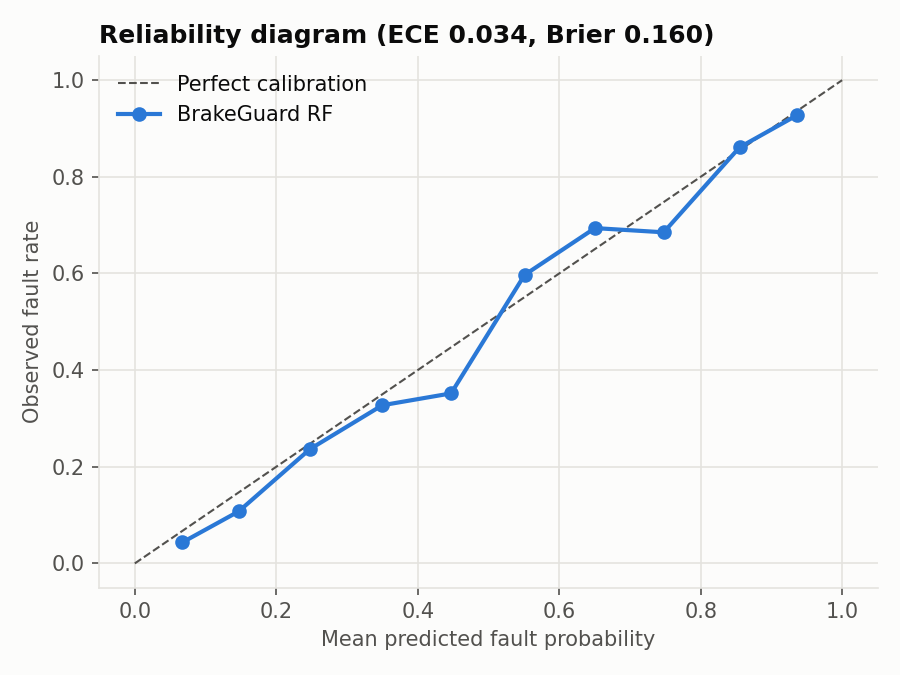

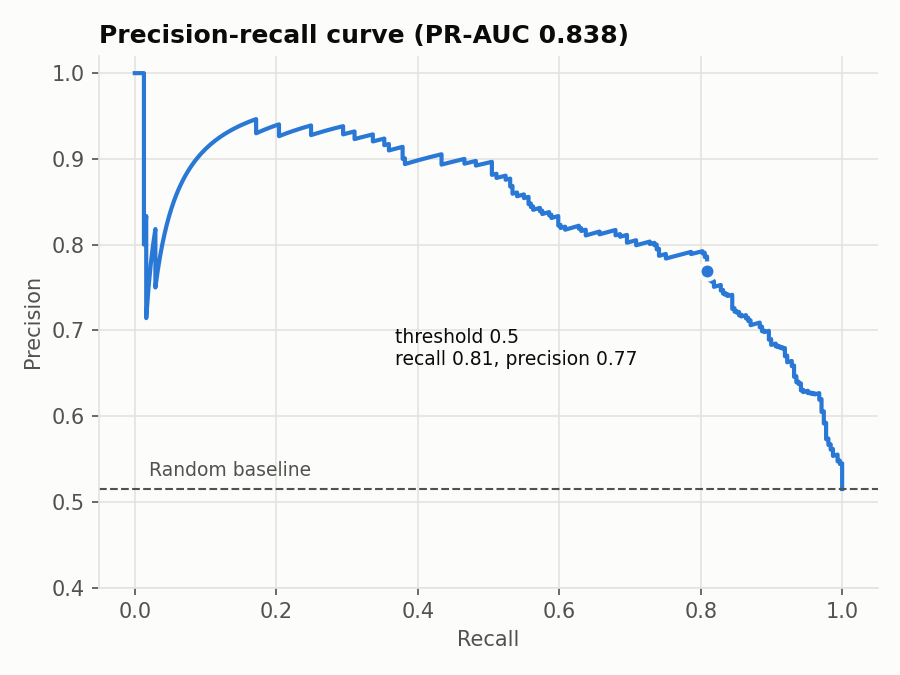

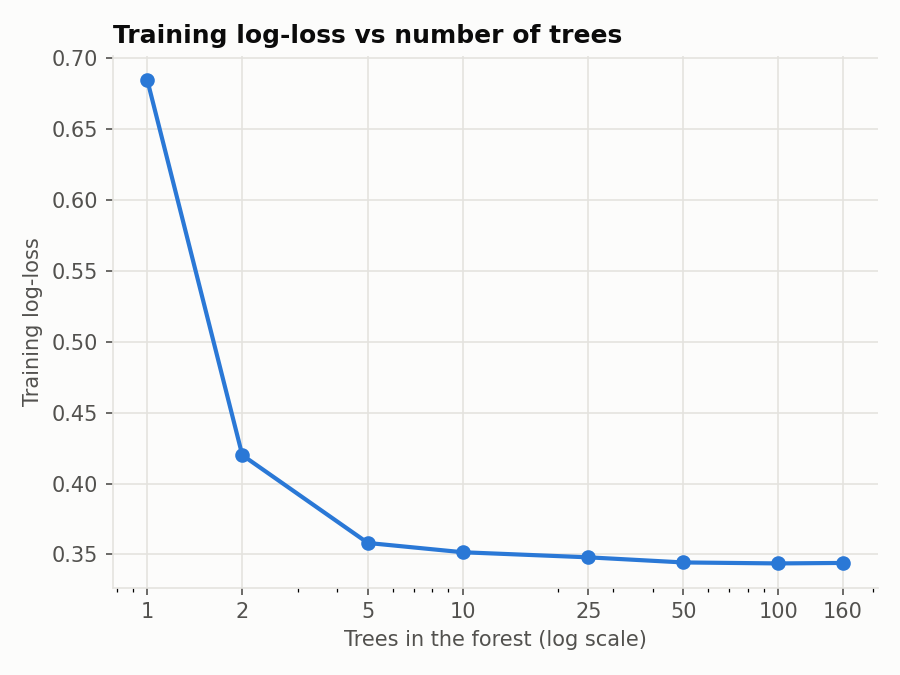

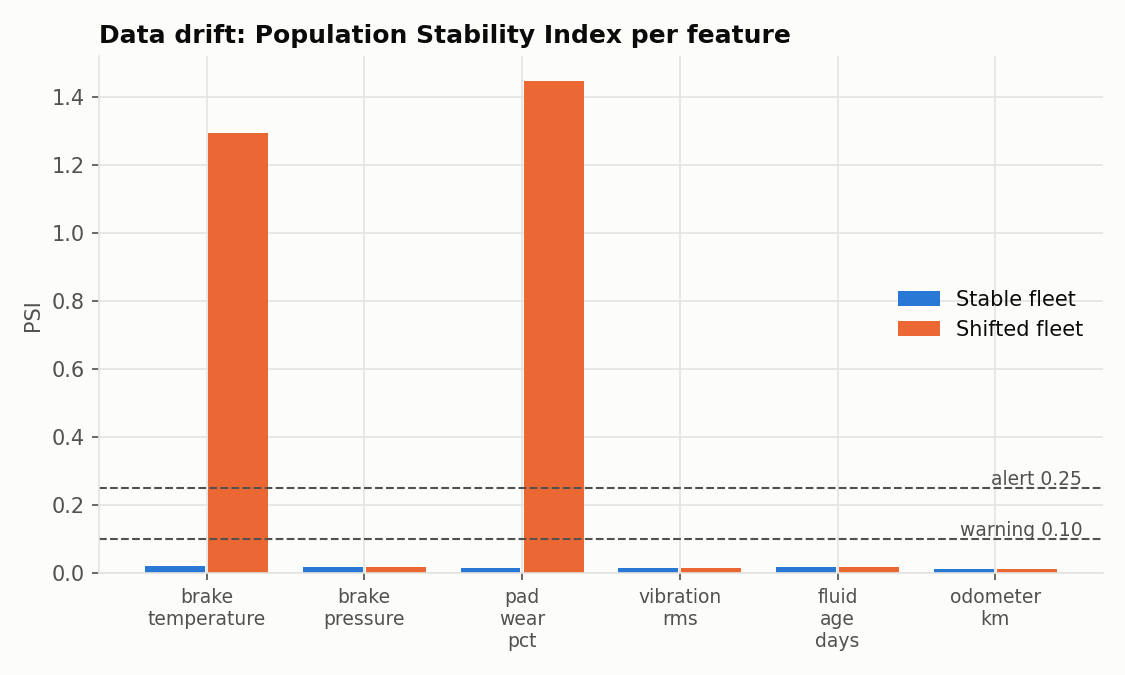

In [115]:
from IPython.display import Image, display
for name in ("calibration.png", "precision_recall.png", "loss_curve.png", "drift_psi.png"):
    display(Image(filename=str(ROOT / "reports/metrics" / name), width=520))

## 6. Test suite (Tasks 6 and 7)

In [116]:
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True)
print(out.stdout[-600:])

........................................................................ [ 75%]
........................                                                 [100%]
96 passed in 15.39s



In [117]:
(ROOT / "artifacts" / "notebook_model.joblib").unlink(missing_ok=True)

## 7. Optional - open the live dashboard, Swagger and charts in your browser (Colab only)

Colab's built-in port proxy and its inline image output both need **third-party cookies**, which
managed (office) browsers often block. This cell avoids both: it starts the API and a small file
server for the charts, then exposes each through a free **Cloudflare quick tunnel** (no account
needed). It prints normal `https://...trycloudflare.com` links that open in any browser tab.
`http://localhost:8000` links do **not** work from your browser: `localhost` is your own PC, while the
API runs on the Colab machine - always use the printed tunnel links.

* The links are public while the cell's processes run - fine for a demo, do not share them widely.
* The processes keep running after the cell finishes - keep this Colab tab open while you use the links.
* **Runtime -> Run all** is safe: the stop cell below only acts when you set `STOP_DEMO = True`.
* If a link shows *Cloudflare error 1033*, the tunnel is not connected: simply re-run this cell.
* When the notebook runs outside Colab these cells do nothing.

In [118]:
import re, time, urllib.request

def _start_tunnel(port, log_name):
    """Start a quick tunnel; return (process, url) once the tunnel is connected, else (process, None)."""
    log = open(ROOT / log_name, "w")
    # --protocol http2 uses plain HTTPS (port 443); more reliable than the default QUIC/UDP on cloud VMs
    proc = subprocess.Popen([str(ROOT / "cloudflared"), "tunnel", "--url", f"http://localhost:{port}",
                             "--no-autoupdate", "--protocol", "http2"], stdout=log, stderr=log)
    url = None
    for _ in range(60):
        time.sleep(1)
        text = (ROOT / log_name).read_text()
        found = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", text)
        url = url or (found.group(0) if found else None)
        if proc.poll() is not None:          # cloudflared exited -> tunnel is dead
            return proc, None
        if url and "Registered tunnel connection" in text:
            time.sleep(3)                    # let the new hostname propagate before printing it
            return proc, url
    return proc, None

if "google.colab" in sys.modules:
    # 1. API + dashboard on port 8000 (loads the registered model, or trains one on first start)
    api_server = subprocess.Popen([sys.executable, "-m", "uvicorn", "app:app", "--port", "8000"], cwd=ROOT,
                                  stdout=open(ROOT / "uvicorn.log", "w"), stderr=subprocess.STDOUT)
    for _ in range(60):
        try:
            urllib.request.urlopen("http://localhost:8000/ready", timeout=2)
            break
        except Exception:
            time.sleep(1)
    # 2. Static file server for the chart PNGs on port 8001
    chart_server = subprocess.Popen([sys.executable, "-m", "http.server", "8001", "--directory", str(ROOT / "reports" / "metrics")],
                                    stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    # 3. Cloudflare quick tunnels (downloads the cloudflared binary once)
    if not (ROOT / "cloudflared").exists():
        subprocess.run(["wget", "-q", "-O", str(ROOT / "cloudflared"),
                        "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64"], check=True)
        (ROOT / "cloudflared").chmod(0o755)
    api_tunnel, api_url = _start_tunnel(8000, "cloudflared_api.log")
    chart_tunnel, chart_url = _start_tunnel(8001, "cloudflared_charts.log")
    print("Dashboard :", api_url or "not ready - see cloudflared_api.log")
    print("Swagger   :", f"{api_url}/docs" if api_url else "-")
    print("Health    :", f"{api_url}/ready" if api_url else "-")
    print("Monitoring:", f"{api_url}/api/v1/monitoring" if api_url else "-")
    print("Charts    :", chart_url or "not ready - see cloudflared_charts.log", "(click a .png)")
else:
    print("Not running in Colab - start the API locally with:  uvicorn app:app  and open http://127.0.0.1:8000")

Dashboard : https://daughter-gem-buys-houston.trycloudflare.com
Swagger   : https://daughter-gem-buys-houston.trycloudflare.com/docs
Health    : https://daughter-gem-buys-houston.trycloudflare.com/ready
Monitoring: https://daughter-gem-buys-houston.trycloudflare.com/api/v1/monitoring
Charts    : https://qualifying-juan-completed-graduated.trycloudflare.com (click a .png)


In [119]:
# Stop the API, chart server and tunnels. Set STOP_DEMO = True and run this cell when you are done.
STOP_DEMO = False

if STOP_DEMO:
    for name in ("api_tunnel", "chart_tunnel", "chart_server", "api_server"):
        proc = globals().get(name)
        if proc is not None:
            proc.terminate()
    print("Demo servers and tunnels stopped")
else:
    print("Demo still running - set STOP_DEMO = True and re-run this cell to stop it")

Demo still running - set STOP_DEMO = True and re-run this cell to stop it
